# Fase 3 — Modelo final y evaluación

Material de apoyo con IA que el grupo debe verificar y comprender. Una fila es una participación real en un accidente; no identidad civil longitudinal ni riesgo por viaje. No se fabrican personas o causalidad.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'protocolo.json').exists())
sys.path.insert(0,str(ROOT/'src'))
from common import OUT,RAW,load_data
if not (RAW/'pessoas_2017.zip').exists() or not (RAW/'pessoas_2026.zip').exists():
    from descargar_fuentes import main as descargar
    descargar()
pd.set_option('display.max_columns',16)
pd.set_option('display.max_colwidth',90)
def tabla(name):return pd.read_csv(OUT/'tables'/name)


## Diseño registrado y comparación obligatoria

Primero se compararon varias familias con 24 entradas: logística, árbol, Bayes y LightGBM más Dummy; 13 configuraciones y 39 ajustes CV. Luego se mejoró preparación/contexto y se compararon ocho LightGBM en tres cortes. El resultado final es un único modelo serializado con 31 características. Las comparaciones permanecen como evidencia exigida por la cátedra.

In [2]:
display(json.loads((ROOT/'protocolo.json').read_text(encoding='utf8')))
from modelado import main as modelar
resultado=modelar()
display(pd.read_csv(OUT/'modelado/inicial/ranking_CV.csv'))
inicial=pd.read_csv(OUT/'modelado/inicial/metricas_prueba_2025.csv')
display(inicial[inicial.regla.eq('F1_validacion')])
display(pd.read_csv(OUT/'modelado/final/ranking_CV.csv'))

{'fecha': '2026-10-31',
 'semilla': 42,
 'pregunta': '¿Qué características personales, vehiculares y del siniestro se asocian con el fallecimiento registrado frente a lesiones no fatales en víctimas de siniestros de PRF Brasil entre 2017 y 2025, y qu? desempeño alcanza su clasificación en el período posterior de 2026?',
 'ganador': 'Contexto_regularizado_natural',
 'predictores': 31,
 'entrenamiento': '2017-2023',
 'calibracion': '2024 enero-junio',
 'umbral': '2024 julio-diciembre',
 'comparacion_retrospectiva': '2025 ya conocido durante la mejora',
 'prueba_final_historica': '2026-01-01 a 2026-09-30; se abrio despues del congelamiento original de la segunda version',
 'nota_reproduccion': 'Los resultados ya fueron observados. Reproducirlos no crea una nueva prueba ciega. Se conservan los registros historicos de seleccion y congelamiento.',
 'inferencia': {'periodo': 'Solo desarrollo 2017-2023',
  'alfa': 0.05,
  'correccion': 'Holm, familia de cuatro contrastes',
  'hipotesis': ['H1:

Resultados finales registrados: se reutilizan sin una nueva seleccion.


,nombre,familia,AP_media,AP_sd,ROC_media,F1_macro_05
0,LightGBM_hojas15_pesoraiz,LightGBM,0.282535,0.003277,0.790511,0.641794
1,LightGBM_hojas15_pesonatural,LightGBM,0.282124,0.005152,0.791835,0.554205
2,LightGBM_hojas31_pesonatural,LightGBM,0.281572,0.003574,0.790195,0.564867
3,LightGBM_hojas31_pesoraiz,LightGBM,0.277738,0.002635,0.786548,0.638081
4,Logistica_natural_C1,Logistica,0.263154,0.003830,0.785398,0.534252
5,Arbol_profundidad10,Arbol,0.260213,0.003867,0.768056,0.554118
6,Logistica_balanceada_C01,Logistica,0.251300,0.005492,0.785298,0.541153
7,Logistica_balanceada_C1,Logistica,0.245877,0.011466,0.781863,0.534829
8,Arbol_profundidad6,Arbol,0.239117,0.003301,0.755250,0.535481
9,Bayes_alpha1,Bayes,0.222457,0.002197,0.760910,0.611983


,modelo,familia,particion,regla,n,fallecidos,prevalencia,umbral,...,balanced_accuracy,accuracy,Brier,log_loss,TN,FP,FN,TP
0,LightGBM_hojas15_pesoraiz,LightGBM,prueba_2025,F1_validacion,89593,6043,0.067449,0.186559,...,0.671377,0.901164,0.054366,0.201626,78286,5264,3591,2452
3,Logistica_natural_C1,Logistica,prueba_2025,F1_validacion,89593,6043,0.067449,0.149459,...,0.688834,0.881899,0.054977,0.203750,76198,7352,3229,2814
6,Arbol_profundidad10,Arbol,prueba_2025,F1_validacion,89593,6043,0.067449,0.148132,...,0.673007,0.887168,0.055522,0.209185,76913,6637,3472,2571
9,Bayes_alpha1,Bayes,prueba_2025,F1_validacion,89593,6043,0.067449,0.161721,...,0.639472,0.893195,0.057016,0.212657,77932,5618,3951,2092
12,LightGBM_solo_sexo_edad,LightGBM_sexo_edad,prueba_2025,F1_validacion,89593,6043,0.067449,0.083473,...,0.570514,0.759713,0.062145,0.241366,65939,17611,3917,2126
15,Logistica_solo_sexo_edad,Logistica_sexo_edad,prueba_2025,F1_validacion,89593,6043,0.067449,0.084066,...,0.571031,0.764256,0.062142,0.241368,66371,17179,3942,2101
18,Dummy_siempre_herido,Dummy,prueba_2025,F1_validacion,89593,6043,0.067449,0.500000,...,0.500000,0.932551,0.062900,0.246991,83550,0,6043,0


,modelo,bloque,AP_media,AP_sd,AUC_media,cortes_supera_referencia,ganancia_AP_media,elegible
0,Contexto_regularizado_natural,contexto,0.338874,0.005573,0.831618,3,0.056339,True
1,Enriquecido_regularizado,enriquecido,0.337457,0.006027,0.830637,3,0.054922,True
2,Enriquecido_mismo_ajuste,enriquecido,0.335749,0.005263,0.829637,3,0.053214,True
3,Enriquecido_7_hojas,enriquecido,0.335503,0.005761,0.830341,3,0.052969,True
4,Enriquecido_31_hojas,enriquecido,0.334509,0.005787,0.828135,3,0.051975,True
5,Contexto_regularizado,contexto,0.334167,0.006001,0.829570,3,0.051632,True
6,Contexto_mismo_ajuste,contexto,0.333749,0.004867,0.829442,3,0.051214,True
7,Referencia_24_original,base,0.282535,0.003277,0.790511,0,0.000000,False


La llamada reutiliza los resultados reales registrados; no vuelve a elegir con 2026. `src/reproducir.py --reentrenar` permite reconstruir los ajustes, que seguirán siendo retrospectivos. Desarrollo 2017–2023; calibración 2024 H1; umbral 2024 H2. La selección final por AP mejoró la referencia en tres cortes. Los congelamientos originales se conservan como evidencia histórica.

In [3]:
display(json.loads((ROOT/'data/metodologia/congelamiento_final_original.json').read_text(encoding='utf8')))
display(pd.read_csv(OUT/'modelado/final/comparacion_completa.csv'))
display(pd.read_csv(OUT/'modelado/final/metricas_evaluacion.csv'))

{'protocolo_sha256': '5c55d2e715ffaa5746c1d5e0f1efc4095e1e6aa84a27872bff9ae90ca8351be0',
 'seleccionado': 'Contexto_regularizado_natural',
 'seleccion_solo_CV': True,
 'modelos': [{'nombre': 'Referencia_24_original',
   'spec': {'nombre': 'Referencia_24_original',
    'bloque': 'base',
    'hojas': 15,
    'arboles': 240,
    'tasa': 0.06,
    'min_hoja': 120,
    'l2': 8,
    'peso': 'raiz'},
   'features': ['sexo',
    'tipo_envolvido',
    'tipo_veiculo',
    'uf',
    'br',
    'municipio',
    'tipo_acidente',
    'fase_dia',
    'sentido_via',
    'condicao_metereologica',
    'tipo_pista',
    'tracado_via',
    'uso_solo',
    'dia_semana',
    'idade',
    'idade_veiculo',
    'hora',
    'hora_sin',
    'hora_cos',
    'mes_sin',
    'mes_cos',
    'latitude',
    'longitude',
    'km'],
   'umbral': 0.18655895245504792,
   'umbrales': {'F1_fallecido': 0.18655895245504792,
    'recall80': 0.04152721383789667},
   'archivo': 'models\\Referencia_24_original.joblib',
   'sha256'

,modelo,particion,regla,n,fallecidos,prevalencia,umbral,AP,...,balanced_accuracy,accuracy,Brier,log_loss,TN,FP,FN,TP
0,Referencia_24_original,entrenamiento_2017_2023,F1_validacion,573747,38619,0.067310,0.186559,0.394759,...,0.710236,0.913044,0.050463,0.182511,505478,29650,20241,18378
1,Referencia_24_original,validacion_umbral_2024_H2,F1_validacion,47236,3252,0.068846,0.186559,0.298293,...,0.670461,0.900182,0.055757,0.207212,41207,2777,1938,1314
2,Contexto_regularizado_natural,entrenamiento_2017_2023,F1_validacion,573747,38619,0.067310,0.214245,0.456459,...,0.723126,0.923935,0.047380,0.170762,511140,23988,19654,18965
3,Contexto_regularizado_natural,validacion_umbral_2024_H2,F1_validacion,47236,3252,0.068846,0.214245,0.357528,...,0.687379,0.913392,0.052972,0.191890,41762,2222,1869,1383
4,Referencia_24_original,2025_retroactivo_ya_conocido,F1_validacion,89593,6043,0.067449,0.186559,0.302314,...,0.671377,0.901164,0.054366,0.201626,78286,5264,3591,2452
5,Referencia_24_original,2025_retroactivo_ya_conocido,umbral_05,89593,6043,0.067449,0.500000,0.302314,...,0.535052,0.933935,0.054366,0.201626,83227,323,5596,447
6,Referencia_24_original,2025_retroactivo_ya_conocido,recall80_validacion,89593,6043,0.067449,0.041527,0.302314,...,0.720063,0.633788,0.054366,0.201626,51829,31721,1089,4954
7,Referencia_24_original,2026_prueba_nueva,F1_validacion,67591,4610,0.068204,0.186559,0.297098,...,0.665797,0.899646,0.055231,0.205224,58987,3994,2789,1821
8,Referencia_24_original,2026_prueba_nueva,umbral_05,67591,4610,0.068204,0.500000,0.297098,...,0.535363,0.933630,0.055231,0.205224,62763,218,4268,342
9,Referencia_24_original,2026_prueba_nueva,recall80_validacion,67591,4610,0.068204,0.041527,0.297098,...,0.713327,0.623678,0.055231,0.205224,38388,24593,843,3767


,modelo,particion,regla,n,fallecidos,prevalencia,umbral,AP,...,balanced_accuracy,accuracy,Brier,log_loss,TN,FP,FN,TP
0,Referencia_24_original,2025_retroactivo_ya_conocido,F1_validacion,89593,6043,0.067449,0.186559,0.302314,...,0.671377,0.901164,0.054366,0.201626,78286,5264,3591,2452
1,Referencia_24_original,2025_retroactivo_ya_conocido,umbral_05,89593,6043,0.067449,0.500000,0.302314,...,0.535052,0.933935,0.054366,0.201626,83227,323,5596,447
2,Referencia_24_original,2025_retroactivo_ya_conocido,recall80_validacion,89593,6043,0.067449,0.041527,0.302314,...,0.720063,0.633788,0.054366,0.201626,51829,31721,1089,4954
3,Referencia_24_original,2026_prueba_nueva,F1_validacion,67591,4610,0.068204,0.186559,0.297098,...,0.665797,0.899646,0.055231,0.205224,58987,3994,2789,1821
4,Referencia_24_original,2026_prueba_nueva,umbral_05,67591,4610,0.068204,0.500000,0.297098,...,0.535363,0.933630,0.055231,0.205224,62763,218,4268,342
5,Referencia_24_original,2026_prueba_nueva,recall80_validacion,67591,4610,0.068204,0.041527,0.297098,...,0.713327,0.623678,0.055231,0.205224,38388,24593,843,3767
6,Contexto_regularizado_natural,2025_retroactivo_ya_conocido,F1_validacion,89593,6043,0.067449,0.214245,0.361358,...,0.689802,0.914770,0.051657,0.187664,79360,4190,3446,2597
7,Contexto_regularizado_natural,2025_retroactivo_ya_conocido,umbral_05,89593,6043,0.067449,0.500000,0.361358,...,0.568642,0.935598,0.051657,0.187664,82950,600,5170,873
8,Contexto_regularizado_natural,2025_retroactivo_ya_conocido,recall80_validacion,89593,6043,0.067449,0.051130,0.361358,...,0.762304,0.722735,0.051657,0.187664,59869,23681,1160,4883
9,Contexto_regularizado_natural,2026_prueba_nueva,F1_validacion,67591,4610,0.068204,0.214245,0.352292,...,0.685806,0.912207,0.052598,0.190564,59704,3277,2657,1953


2025 es retrospectivo porque ya se conocían sus resultados al mejorar. El corte 2026 fue abierto después del congelamiento original; cubre enero–septiembre, no el año entero. Ambos modelos se ajustaron con los mismos períodos y se comparan sobre idénticas víctimas. Se conserva prevalencia natural y se excluyen IDs, desenlace, gravedad y conteos de víctimas de las entradas.

In [4]:
from graficos import main as analizar
interpretaciones=analizar()
display(tabla('importancia_modelo_final.csv'))

,variable,caida_AP_media,sd,particion,n
0,tipo_acidente,0.135564,0.004673,validacion_2024_H2,10000
1,tipo_veiculo,0.112593,0.001355,validacion_2024_H2,10000
2,otros_pesados,0.042164,0.000635,validacion_2024_H2,10000
3,municipio,0.037686,0.005069,validacion_2024_H2,10000
4,n_vehiculos_declarados,0.028720,0.002217,validacion_2024_H2,10000
5,familia_otro_vehiculo,0.024007,0.003941,validacion_2024_H2,10000
6,uso_solo,0.018619,0.000207,validacion_2024_H2,10000
7,tipo_envolvido,0.012980,0.005547,validacion_2024_H2,10000
8,n_otros_vehiculos,0.012345,0.000264,validacion_2024_H2,10000
9,idade,0.010563,0.000863,validacion_2024_H2,10000


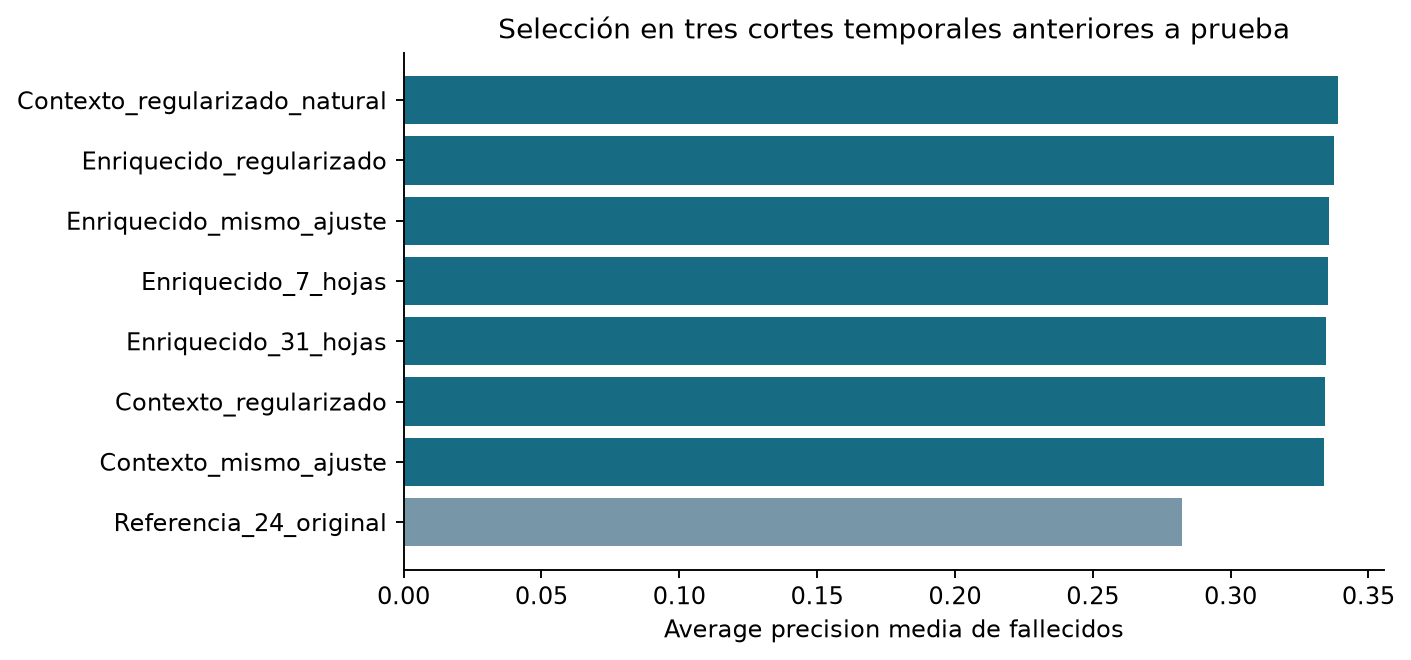

In [5]:
display(Image(filename=str(OUT/'figures/01_busqueda_CV.png')))

Se compararon ocho configuraciones en tres cortes anteriores a prueba. La variante elegida supera la referencia en los tres cortes; la grilla no se amplio mirando 2026.

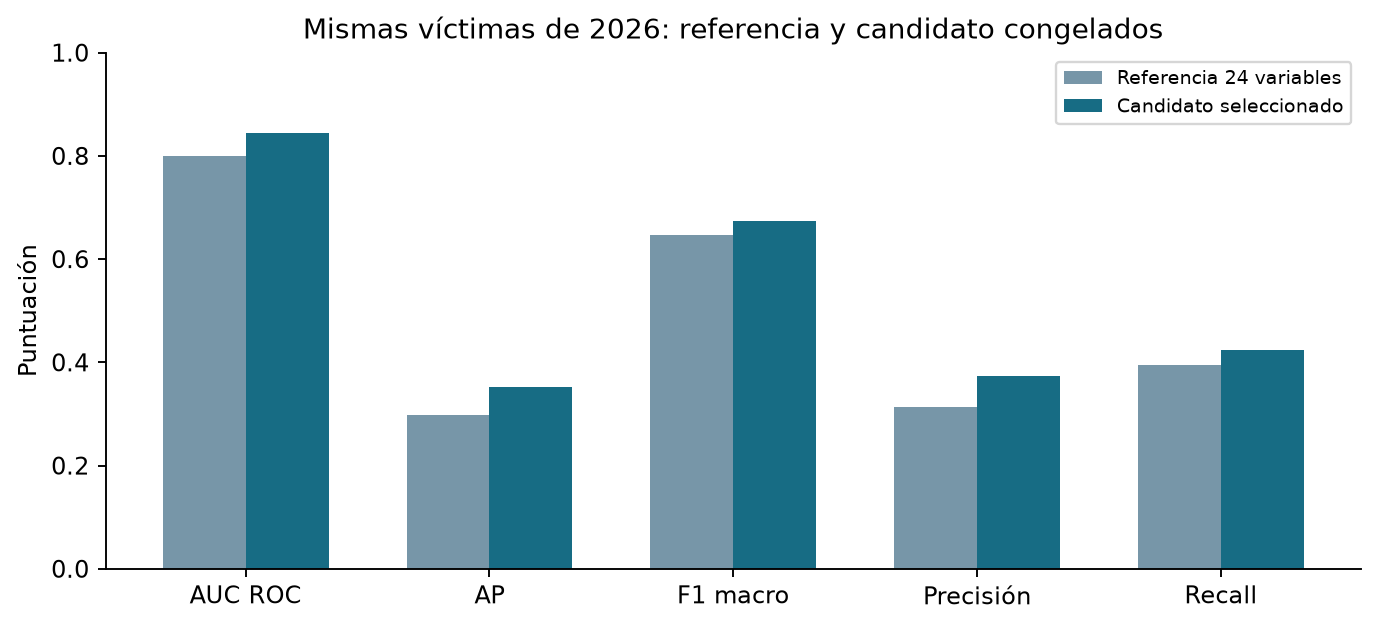

In [6]:
display(Image(filename=str(OUT/'figures/02_comparacion_2026.png')))

Sobre las mismas victimas de enero a septiembre de 2026, la version de 31 variables mejora AUC, AP, F1 macro, precision y recall. Los umbrales se fijaron con 2024 y se conserva prevalencia natural.

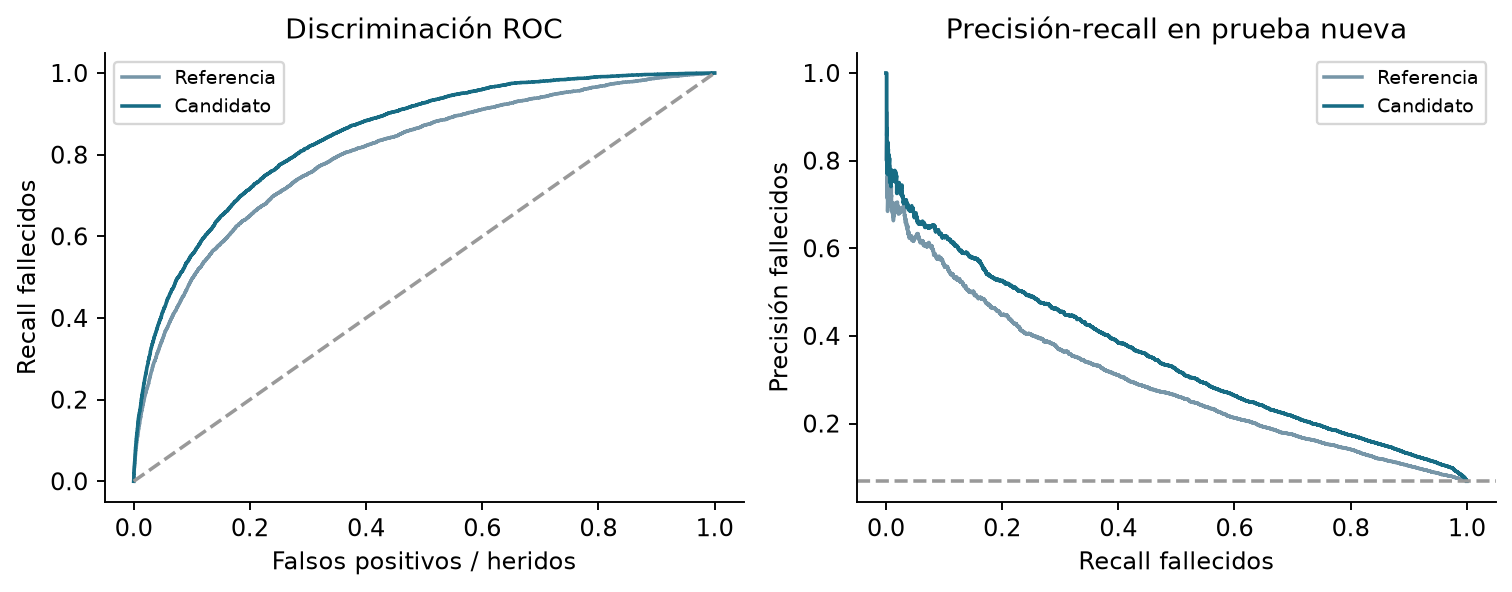

In [7]:
display(Image(filename=str(OUT/'figures/03_curvas_2026.png')))

La curva precision-recall del candidato muestra mejor ordenamiento de la clase minoritaria. La prevalencia sigue influyendo en precision y AP; AUC 0,845 no equivale a detectar el 84,5% de fallecidos.

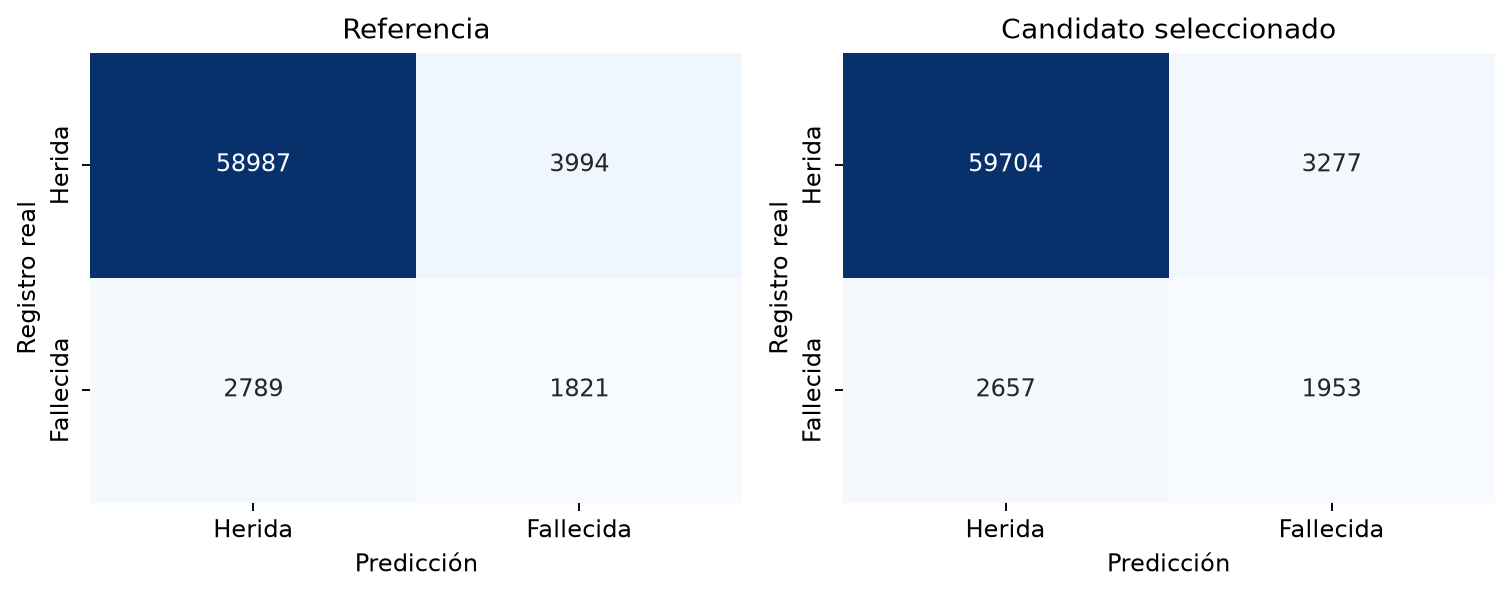

In [8]:
display(Image(filename=str(OUT/'figures/04_confusion_2026.png')))

El modelo final detecta 1.953 de 4.610 fallecidos y omite 2.657; produce 3.277 falsas alarmas. Frente a la referencia son 132 detecciones mas y 717 falsas alarmas menos, sin cambiar reglas con prueba.

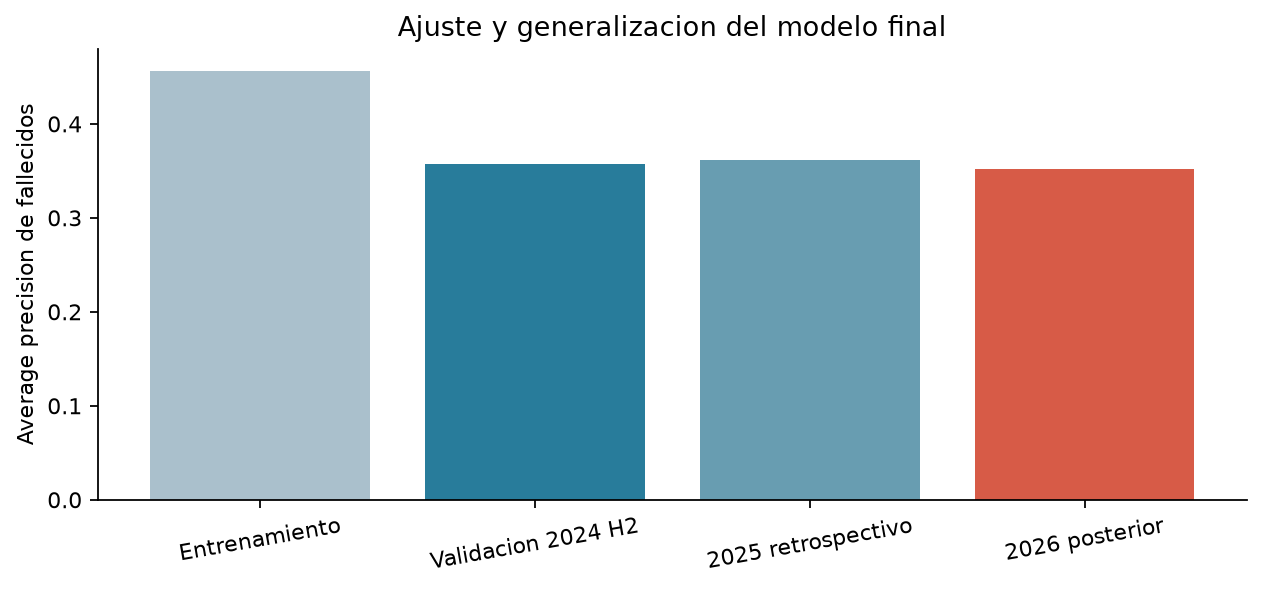

In [9]:
display(Image(filename=str(OUT/'figures/f3_05_generalizacion.png')))

AP de entrenamiento 0,456 frente a 0,358 en validacion y 0,352 en 2026 muestra optimismo del ajuste. La estabilidad entre periodos posteriores es favorable, sin garantizar que desaparezcan sobreajuste o cambios de registro.

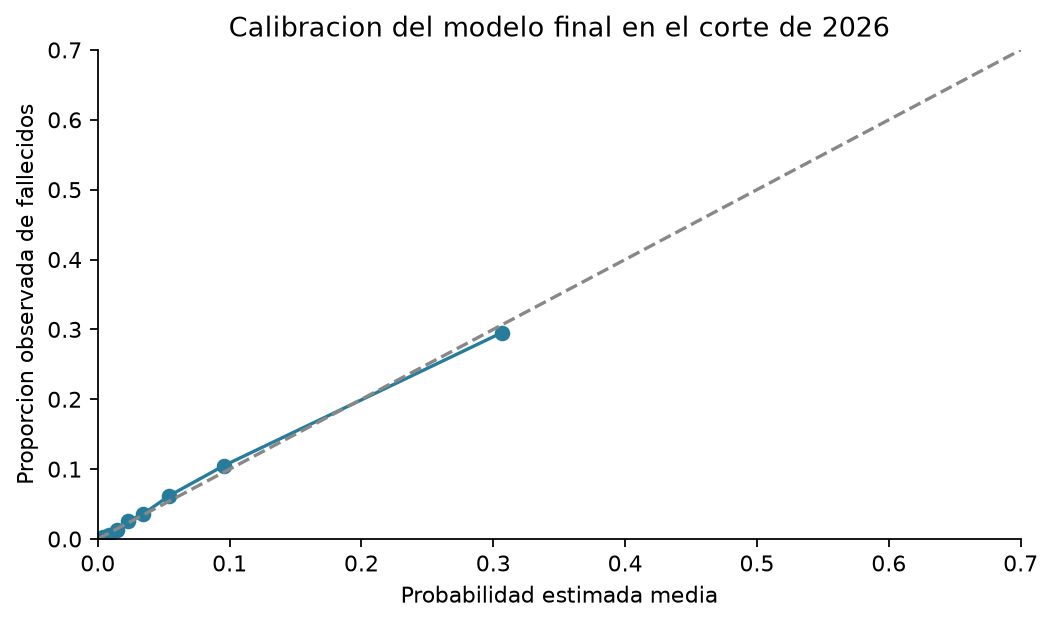

In [10]:
display(Image(filename=str(OUT/'figures/f3_06_calibracion.png')))

La sigmoid se ajusto en 2024 H1 con prevalencia natural. El grafico evalua fiabilidad por grupos de puntuaciones; no implica certeza individual. Brier y log loss complementan, sin aislar calibracion de todos los otros componentes.

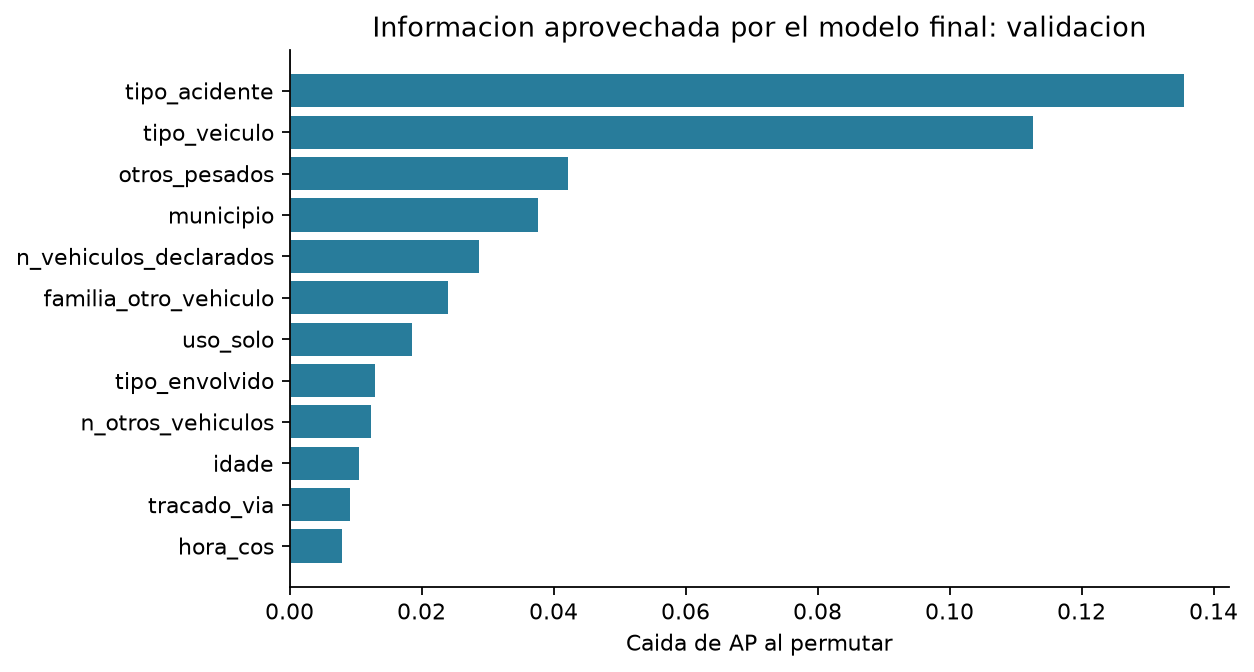

In [11]:
display(Image(filename=str(OUT/'figures/f3_07_importancia.png')))

La importancia se calcula en 10.000 casos de validacion, con dos repeticiones; no se eligen variables usando prueba. Las variables correlacionadas pueden sustituirse y compartir importancia. Utilidad predictiva no demuestra causalidad.

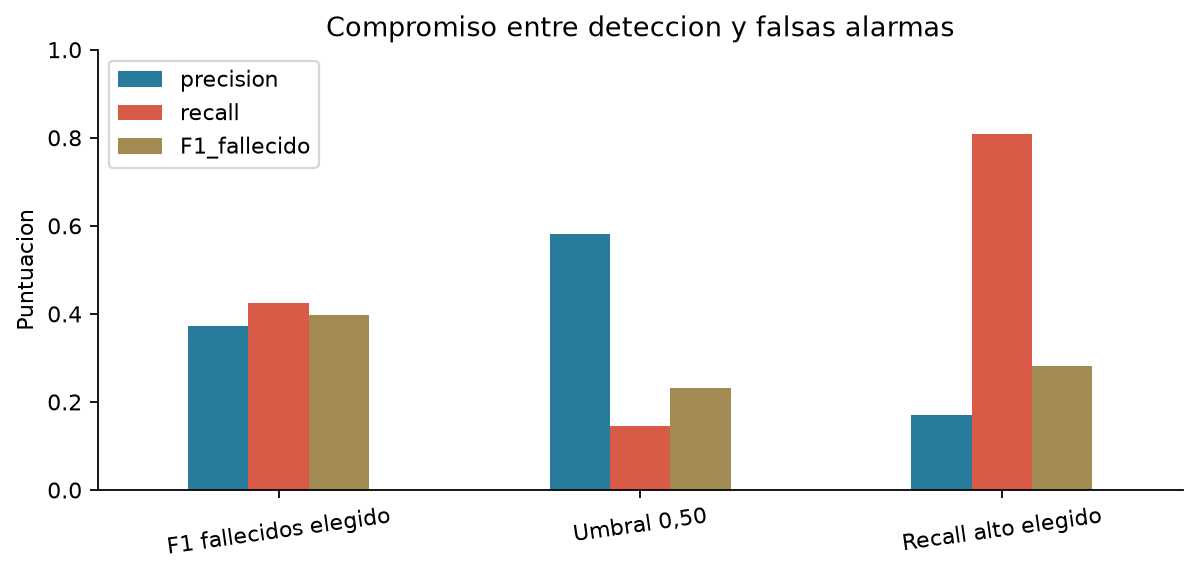

In [12]:
display(Image(filename=str(OUT/'figures/f3_08_umbrales.png')))

El umbral principal detecta 42,36% de fallecidos con precision 37,34%. La regla de mayor deteccion alcanza 80,95% con precision 17,03%. Ambas se definieron con validacion; ninguna representa una politica clinica aprobada.

In [13]:
display(tabla('errores_por_grupo_modelo_final.csv'))
display(tabla('errores_mayor_confianza_modelo_final.csv').drop(columns=['id','pesid']))
display(pd.read_csv(OUT/'modelado/final/intervalos_mejora_2026.csv'))

,variable,grupo,n,fallecidos,prevalencia,umbral,AP,ROC_AUC,...,balanced_accuracy,accuracy,Brier,log_loss,TN,FP,FN,TP
0,sexo,FEMININO,19996,901,0.045059,0.214245,0.270327,0.842125,...,0.636448,0.943889,0.037373,0.144217,18605,490,632,269
1,sexo,MASCULINO,47531,3689,0.077613,0.214245,0.370830,0.840980,...,0.695480,0.899203,0.058778,0.209351,41064,2778,2013,1676
2,grupo_edad,1-17,3275,145,0.044275,0.214245,0.251092,0.831910,...,0.625151,0.943511,0.037348,0.145035,3050,80,105,40
3,grupo_edad,18-29,19367,956,0.049362,0.214245,0.304453,0.852832,...,0.665809,0.935922,0.039754,0.150314,17776,635,606,350
4,grupo_edad,30-44,21891,1317,0.060162,0.214245,0.342536,0.843833,...,0.686130,0.920333,0.046957,0.174215,19594,980,764,553
5,grupo_edad,45-59,13802,1145,0.082959,0.214245,0.348180,0.829498,...,0.677653,0.891755,0.064217,0.226004,11826,831,663,482
6,grupo_edad,60-110,7506,794,0.105782,0.214245,0.386666,0.806308,...,0.687868,0.866773,0.078879,0.272876,6140,572,428,366
7,tipo_envolvido,CONDUTOR,43690,2917,0.066766,0.214245,0.347800,0.845009,...,0.679536,0.914260,0.051726,0.187808,38752,2021,1725,1192
8,tipo_envolvido,PASSAGEIRO,21571,1035,0.047981,0.214245,0.190822,0.803749,...,0.595207,0.936767,0.042162,0.163081,19982,554,810,225
9,tipo_envolvido,PEDESTRE,2319,656,0.282881,0.214245,0.552752,0.775394,...,0.698374,0.646831,0.165421,0.496286,964,699,120,536


,fallecido,idade,sexo,tipo_envolvido,tipo_veiculo,familia_otro_vehiculo,Contexto_regularizado_natural,tipo_error,confianza_erronea
0,1,25.0,MASCULINO,CONDUTOR,MOTOCICLETA,LIGERO,0.001908,FN,0.998092
1,1,31.0,MASCULINO,CONDUTOR,MOTOCICLETA,LIGERO,0.003140,FN,0.996860
2,1,25.0,MASCULINO,CONDUTOR,MOTOCICLETA,NINGUNO_IDENTIFICADO,0.003219,FN,0.996781
3,1,22.0,MASCULINO,PASSAGEIRO,AUTOMOVEL,LIGERO,0.003706,FN,0.996294
4,1,20.0,FEMININO,PASSAGEIRO,MOTOCICLETA,MOTO,0.003837,FN,0.996163
5,1,40.0,MASCULINO,CONDUTOR,MOTONETA,LIGERO,0.003843,FN,0.996157
6,1,19.0,FEMININO,PASSAGEIRO,MOTOCICLETA,NINGUNO_IDENTIFICADO,0.004063,FN,0.995937
7,1,26.0,FEMININO,PASSAGEIRO,MOTOCICLETA,MOTO,0.004232,FN,0.995768
8,1,21.0,MASCULINO,CONDUTOR,MOTOCICLETA,MOTO,0.004289,FN,0.995711
9,1,34.0,MASCULINO,CONDUTOR,MOTOCICLETA,LIGERO,0.004724,FN,0.995276


,metrica,IC95_bajo,IC95_alto
0,delta_AP,0.047294,0.062425
1,delta_ROC_AUC,0.041235,0.049923
2,delta_F1_macro,0.021603,0.032713
3,delta_precision,0.050074,0.069804
4,delta_recall,0.016494,0.041310


## Conclusión

En 2026 AUC pasa de 0,799 a 0,845 y F1 macro de 0,647 a 0,675. El ganador detecta 132 fallecidos más y produce 717 falsas alarmas menos que la referencia. Todavía omite 2.657 fallecidos y genera 3.277 falsas alarmas. El umbral alto recall sacrifica precisión; la decisión práctica depende de costos no definidos. Las características se conocen después del siniestro, no se predice quién se accidentará. Uso académico; no causalidad ni validación clínica o para Paraguay.